In [ ]:
!pip install catboost -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
np.random.seed(42)
n_samples = 2000

data = {
    'tenure': np.random.randint(1, 72, n_samples),  # months
    'monthly_charges': np.random.uniform(20, 120, n_samples),
    'total_charges': np.random.uniform(100, 8000, n_samples),
    'contract_type': np.random.choice(['Month-to-month', 'One year', 'Two year'], n_samples, p=[0.5, 0.25, 0.25]),
    'tech_support': np.random.choice(['Yes', 'No'], n_samples, p=[0.4, 0.6]),
    'number_of_support_calls': np.random.randint(0, 6, n_samples)
}

df = pd.DataFrame(data)

# Create a synthetic relationship for Churn (1 = Churn, 0 = Retained)
# Probability increases with high monthly charges, many support calls, month-to-month contract, and low tenure
logit = (
    0.02 * df['monthly_charges']
    + 0.5 * df['number_of_support_calls']
    - 0.08 * df['tenure']
    + (df['contract_type'] == 'Month-to-month').astype(int) * 1.5
    - (df['tech_support'] == 'Yes').astype(int) * 0.5
    - 2.5
)
prob = 1 / (1 + np.exp(-logit))
df['churn'] = (np.random.rand(n_samples) < prob).astype(int)

display(df.head())
print(f"Churn Distribution:\n{df['churn'].value_counts(normalize=True)}")

,tenure,monthly_charges,total_charges,contract_type,tech_support,number_of_support_calls,churn
0,52,45.467062,5290.540936,Two year,No,4,0
1,15,104.087158,7197.253086,Month-to-month,No,3,1
2,61,23.842635,3256.198398,One year,No,2,0
3,21,110.176199,2681.678176,Month-to-month,Yes,3,0
4,24,66.147746,185.407561,One year,No,0,0


Churn Distribution:
churn
0    0.7735
1    0.2265
Name: proportion, dtype: float64


In [ ]:
X = df.drop('churn', axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ['tenure', 'monthly_charges', 'total_charges', 'number_of_support_calls']
cat_cols = ['contract_type', 'tech_support']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names after encoding
encoded_cat_features = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(encoded_cat_features)

print("Preprocessed data shape:", X_train_preprocessed.shape)

Preprocessed data shape: (1600, 7)


In [ ]:
results = {}

def evaluate_model(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    print(f"=== {name} Performance ===")
    print(classification_report(y_true, y_pred))
    return confusion_matrix(y_true, y_pred)

In [ ]:
# 1. Logistic Regression
lr = LogisticRegression(random_state=42)
lr.fit(X_train_preprocessed, y_train)
lr_preds = lr.predict(X_test_preprocessed)
lr_probs = lr.predict_proba(X_test_preprocessed)[:, 1]
lr_cm = evaluate_model('Logistic Regression', y_test, lr_preds, lr_probs)

# 2. Random Forest
rf = RandomForestClassifier(random_state=42, n_estimators=100)
rf.fit(X_train_preprocessed, y_train)
rf_preds = rf.predict(X_test_preprocessed)
rf_probs = rf.predict_proba(X_test_preprocessed)[:, 1]
rf_cm = evaluate_model('Random Forest', y_test, rf_preds, rf_probs)

# 3. XGBoost
xgb = XGBClassifier(random_state=42, eval_metric='logloss')
xgb.fit(X_train_preprocessed, y_train)
xgb_preds = xgb.predict(X_test_preprocessed)
xgb_probs = xgb.predict_proba(X_test_preprocessed)[:, 1]
xgb_cm = evaluate_model('XGBoost', y_test, xgb_preds, xgb_probs)

# 4. CatBoost
cat = CatBoostClassifier(random_state=42, verbose=0)
cat.fit(X_train_preprocessed, y_train)
cat_preds = cat.predict(X_test_preprocessed)
cat_probs = cat.predict_proba(X_test_preprocessed)[:, 1]
cat_cm = evaluate_model('CatBoost', y_test, cat_preds, cat_probs)

=== Logistic Regression Performance ===
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       309
           1       0.75      0.56      0.64        91

    accuracy                           0.86       400
   macro avg       0.81      0.75      0.78       400
weighted avg       0.85      0.86      0.85       400

=== Random Forest Performance ===
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       309
           1       0.68      0.52      0.59        91

    accuracy                           0.83       400
   macro avg       0.77      0.72      0.74       400
weighted avg       0.82      0.83      0.83       400

=== XGBoost Performance ===
              precision    recall  f1-score   support

           0       0.87      0.92      0.89       309
           1       0.65      0.54      0.59        91

    accuracy                           0.83       400
   macro avg       0.76   

In [ ]:
# 5. Artificial Neural Network (ANN)
ann = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_preprocessed.shape[1],)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

ann.fit(
    X_train_preprocessed, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=0
)

ann_probs = ann.predict(X_test_preprocessed).flatten()
ann_preds = (ann_probs > 0.5).astype(int)
ann_cm = evaluate_model('ANN', y_test, ann_preds, ann_probs)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
=== ANN Performance ===
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       309
           1       0.74      0.58      0.65        91

    accuracy                           0.86       400
   macro avg       0.81      0.76      0.78       400
weighted avg       0.85      0.86      0.85       400



,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.857500,0.750000,0.560440,0.641509,0.915609
Random Forest,0.835000,0.681159,0.516484,0.587500,0.869270
XGBoost,0.830000,0.653333,0.538462,0.590361,0.861304
CatBoost,0.857500,0.736111,0.582418,0.650307,0.884491
ANN,0.857500,0.736111,0.582418,0.650307,0.908994


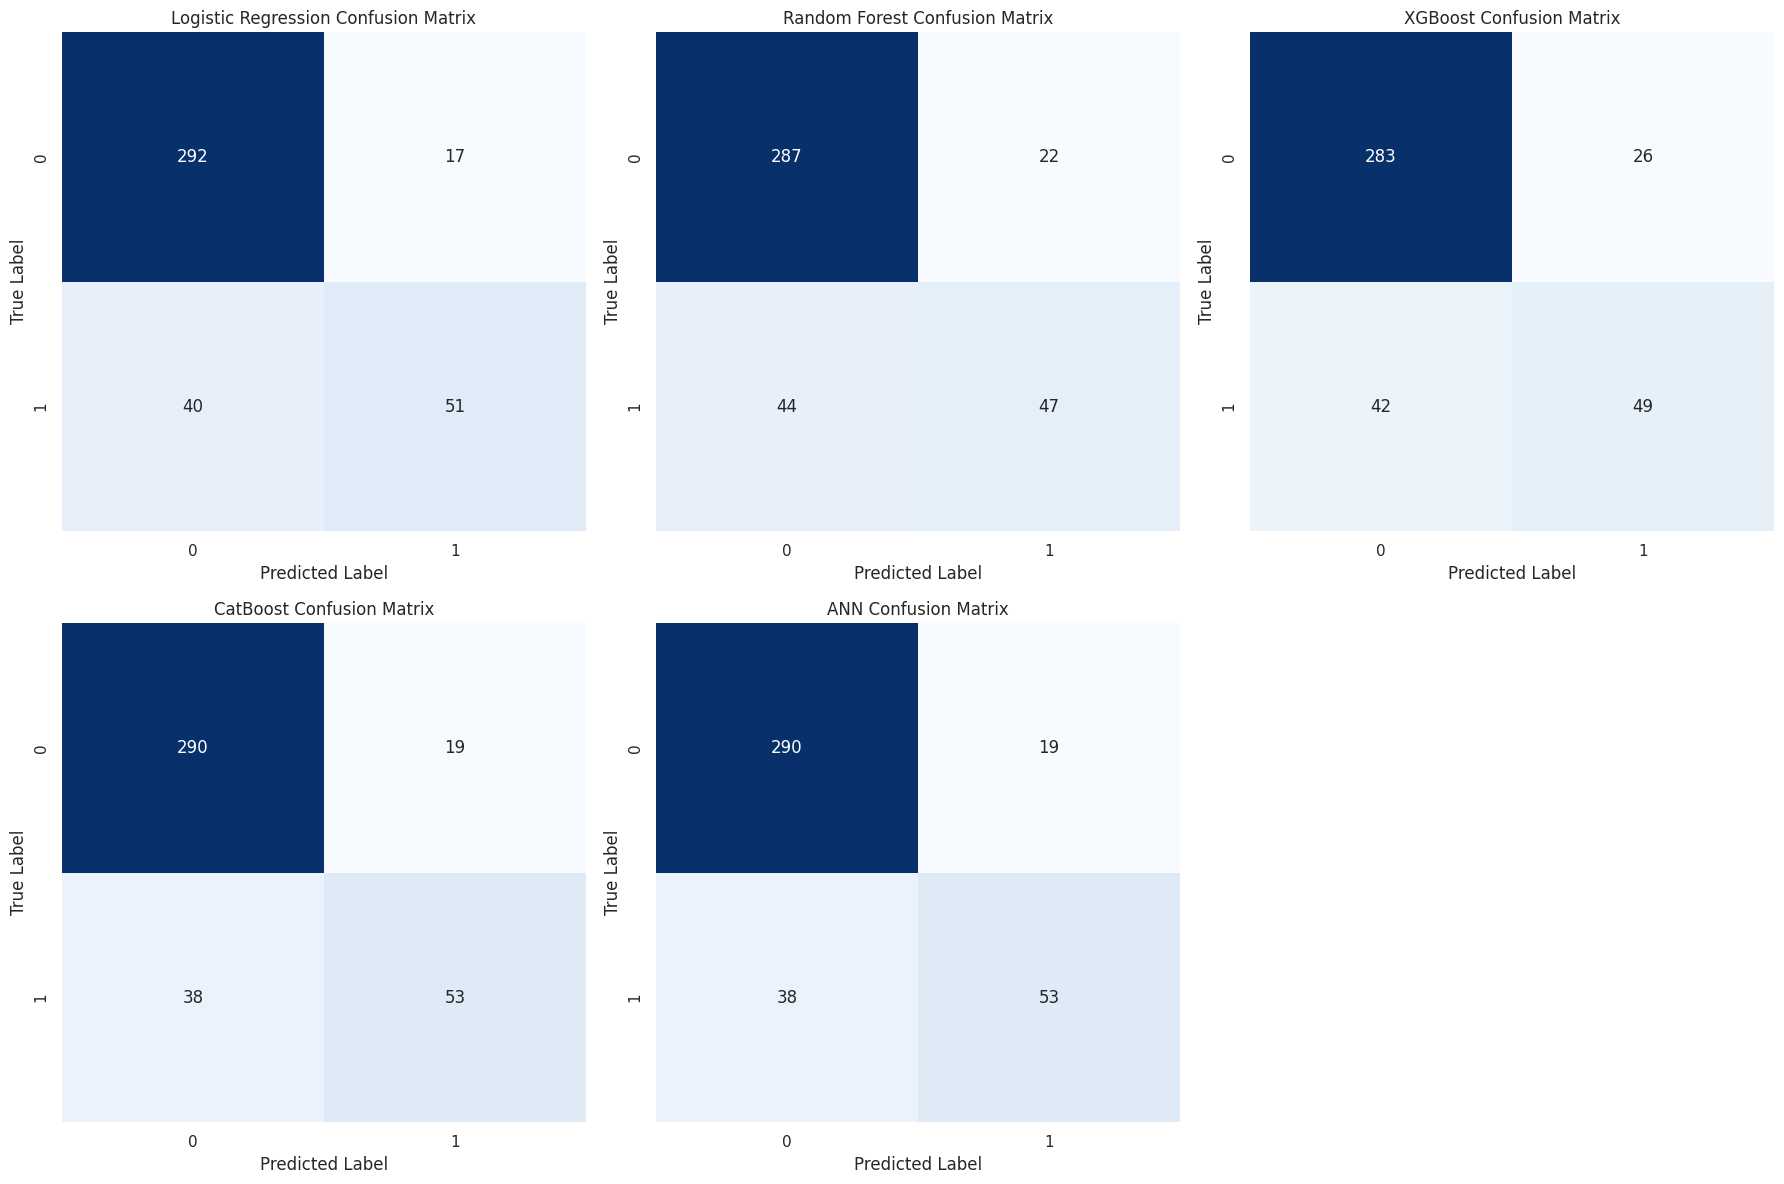

In [ ]:
# Compare metrics
results_df = pd.DataFrame(results).T
display(results_df.style.highlight_max(color='lightgreen', axis=0))

# Plot Confusion Matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
matrices = [
    ('Logistic Regression', lr_cm),
    ('Random Forest', rf_cm),
    ('XGBoost', xgb_cm),
    ('CatBoost', cat_cm),
    ('ANN', ann_cm)
]

for i, (name, cm) in enumerate(matrices):
    ax = axes[i // 3, i % 3]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')

# Hide the last empty subplot
axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

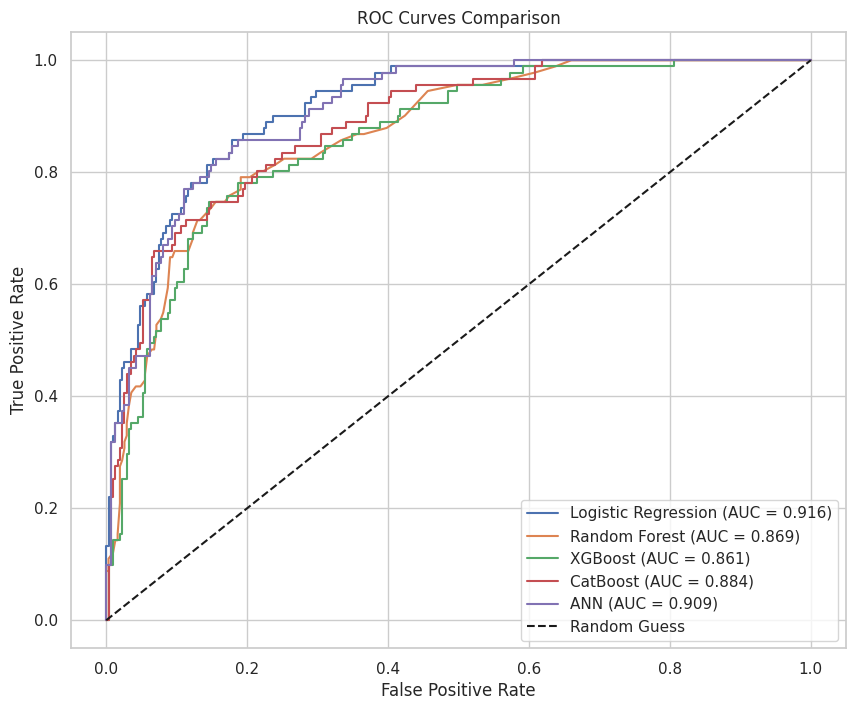

In [ ]:
# Plot ROC Curves
plt.figure(figsize=(10, 8))

models_probs = [
    ('Logistic Regression', lr_probs),
    ('Random Forest', rf_probs),
    ('XGBoost', xgb_probs),
    ('CatBoost', cat_probs),

    ('ANN', ann_probs)
]

for name, probs in models_probs:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.show()

### ✨ UX/UI Design & Presentation Improvements
In this section, we apply some UI/UX and styling updates to make our figures and tables highly readable and visually striking.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Sleek, custom-styled table for results comparison
slick_results_df = results_df.copy()

# Format numbers elegantly
styled_table = (slick_results_df.style
    .format('{:.3f}')
    .background_gradient(cmap='Blues', subset=['Accuracy', 'F1-Score', 'ROC-AUC'])
    .set_properties(**{
        'font-family': 'Segoe UI, sans-serif',
        'font-size': '13px',
        'border-collapse': 'collapse',
        'border': '1px solid #e0e0e0'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1a365d'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('padding', '10px'), ('text-align', 'center')]},
        {'selector': 'tr:nth-of-type(odd)', 'props': [('background-color', '#f7fafc')]},
        {'selector': 'tr:hover', 'props': [('background-color', '#edf2f7')]}
    ])
)

print("=== Beautiful Model Comparison ===")
display(styled_table)

=== Beautiful Model Comparison ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.858,0.750,0.560,0.642,0.916
Random Forest,0.835,0.681,0.516,0.588,0.869
XGBoost,0.830,0.653,0.538,0.590,0.861
CatBoost,0.858,0.736,0.582,0.650,0.884
ANN,0.858,0.736,0.582,0.650,0.909


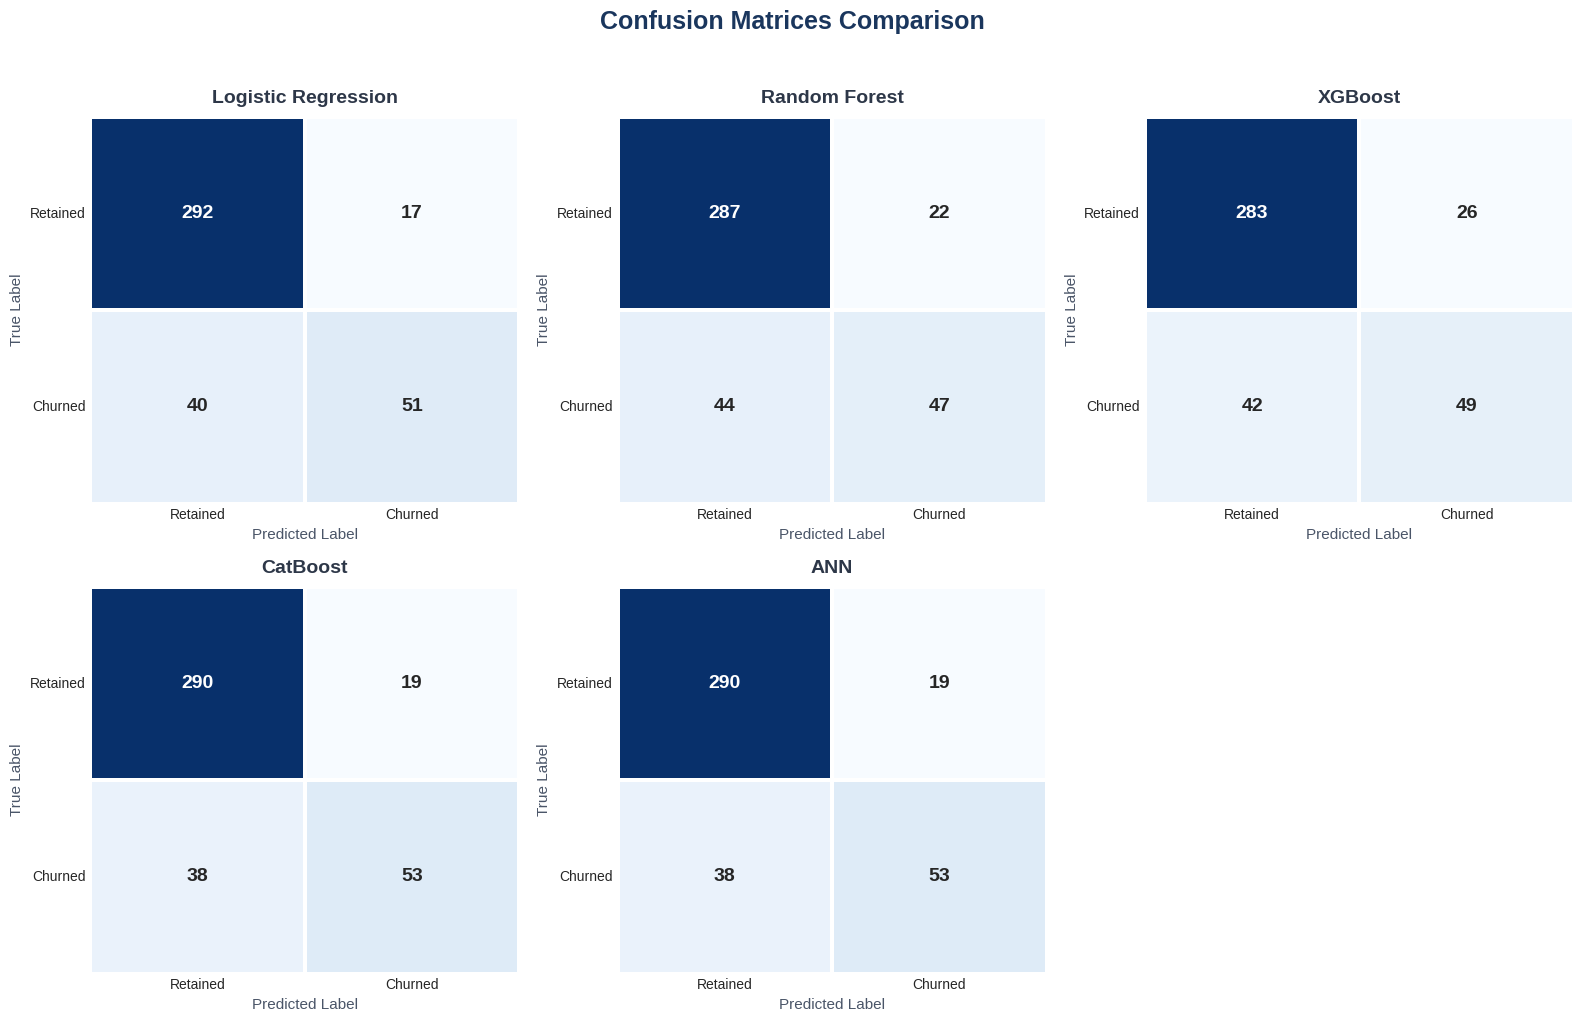

In [ ]:
# 2. Polished Confusion Matrices Visualization
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Confusion Matrices Comparison', fontsize=18, fontweight='bold', color='#1a365d', y=1.02)

matrices = [
    ('Logistic Regression', lr_cm),
    ('Random Forest', rf_cm),
    ('XGBoost', xgb_cm),
    ('CatBoost', cat_cm),
    ('ANN', ann_cm)
]

for i, (name, cm) in enumerate(matrices):
    ax = axes[i // 3, i % 3]
    # Clean and highly contrastive palette
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='white')

    ax.set_title(name, fontsize=14, fontweight='semibold', pad=10, color='#2d3748')
    ax.set_ylabel('True Label', fontsize=11, fontweight='medium', color='#4a5568')
    ax.set_xlabel('Predicted Label', fontsize=11, fontweight='medium', color='#4a5568')
    ax.tick_params(labelsize=10)
    ax.set_xticklabels(['Retained', 'Churned'])
    ax.set_yticklabels(['Retained', 'Churned'], rotation=0)

# Hide the last empty subplot
axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

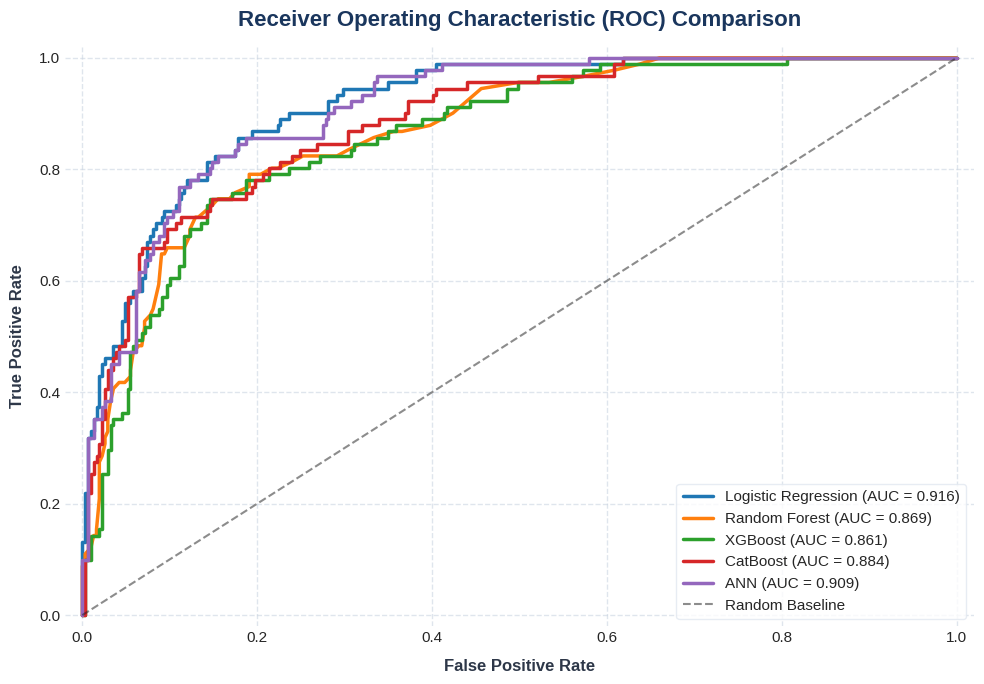

In [ ]:
# 3. High-Quality Professional ROC Curves Comparison
plt.figure(figsize=(10, 7), dpi=100)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for idx, (name, probs) in enumerate(models_probs):
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=colors[idx], linewidth=2.5)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline')

# Aesthetics optimization
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate', fontsize=12, labelpad=10, fontweight='semibold', color='#2d3748')
plt.ylabel('True Positive Rate', fontsize=12, labelpad=10, fontweight='semibold', color='#2d3748')
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontsize=16, fontweight='bold', pad=15, color='#1a365d')

plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#e2e8f0', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6, color='#cbd5e1')
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

In [ ]:
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data for dashboard interaction
model_eval_data = {
    'Logistic Regression': {'preds': lr_preds, 'probs': lr_probs, 'cm': lr_cm},
    'Random Forest': {'preds': rf_preds, 'probs': rf_probs, 'cm': rf_cm},
    'XGBoost': {'preds': xgb_preds, 'probs': xgb_probs, 'cm': xgb_cm},
    'CatBoost': {'preds': cat_preds, 'probs': cat_probs, 'cm': cat_cm},
    'ANN': {'preds': ann_preds, 'probs': ann_probs, 'cm': ann_cm}
}

def render_dashboard(model_name):
    # Extract stats
    metrics = results_df.loc[model_name]
    data = model_eval_data[model_name]

    # Display Styled HTML Performance Card
    html_card = f"""
    <div style="padding: 15px; border-radius: 8px; background-color: #f7fafc; border: 1px solid #e2e8f0; font-family: sans-serif; margin-bottom: 20px;">
        <h3 style="color: #1a365d; margin-top: 0;">☑️ {model_name} Performance Cards</h3>
        <div style="display: flex; gap: 20px; flex-wrap: wrap;">
            <div style="background: white; padding: 10px 15px; border-radius: 6px; border: 1px solid #edf2f7; text-align: center; min-width: 100px;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Accuracy</span><br/>
                <strong style="font-size: 18px; color: #2b6cb0;">{metrics['Accuracy']:.1%}</strong>
            </div>
            <div style="background: white; padding: 10px 15px; border-radius: 6px; border: 1px solid #edf2f7; text-align: center; min-width: 100px;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Precision</span><br/>
                <strong style="font-size: 18px; color: #2b6cb0;">{metrics['Precision']:.1%}</strong>
            </div>
            <div style="background: white; padding: 10px 15px; border-radius: 6px; border: 1px solid #edf2f7; text-align: center; min-width: 100px;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Recall</span><br/>
                <strong style="font-size: 18px; color: #2b6cb0;">{metrics['Recall']:.1%}</strong>
            </div>
            <div style="background: white; padding: 10px 15px; border-radius: 6px; border: 1px solid #edf2f7; text-align: center; min-width: 100px;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">F1-Score</span><br/>
                <strong style="font-size: 18px; color: #2b6cb0;">{metrics['F1-Score']:.3f}</strong>
            </div>
            <div style="background: white; padding: 10px 15px; border-radius: 6px; border: 1px solid #edf2f7; text-align: center; min-width: 100px;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">ROC-AUC</span><br/>
                <strong style="font-size: 18px; color: #2b6cb0;">{metrics['ROC-AUC']:.3f}</strong>
            </div>
        </div>
    </div>
    """
    display(widgets.HTML(html_card))

    # Plot Visualizations
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Plot Confusion Matrix
    sns.heatmap(data['cm'], annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='white')
    ax1.set_title(f'{model_name} Confusion Matrix', fontsize=13, fontweight='semibold', color='#2d3748', pad=12)
    ax1.set_xticklabels(['Retained', 'Churned'])
    ax1.set_yticklabels(['Retained', 'Churned'], rotation=0)
    ax1.set_xlabel('Predicted Label', fontweight='medium')
    ax1.set_ylabel('True Label', fontweight='medium')

    # Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, data['probs'])
    auc_val = roc_auc_score(y_test, data['probs'])
    ax2.plot(fpr, tpr, color='#1f77b4', linewidth=2.5, label=f"{model_name} (AUC = {auc_val:.3f})")
    ax2.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline')
    ax2.set_xlim([-0.02, 1.02])
    ax2.set_ylim([-0.02, 1.02])
    ax2.set_title(f'{model_name} ROC Curve', fontsize=13, fontweight='semibold', color='#2d3748', pad=12)
    ax2.set_xlabel('False Positive Rate')
    ax2.set_ylabel('True Positive Rate')
    ax2.legend(loc='lower right', frameon=True, edgecolor='#e2e8f0')
    ax2.grid(True, linestyle='--', alpha=0.6, color='#cbd5e1')

    plt.tight_layout()
    plt.show()

# Render Interactive Dropdown Menu
style_dropdown = widgets.Dropdown(
    options=list(model_eval_data.keys()),
    value='ANN',
    description='Select Model:',
    disabled=False,
    style={'description_width': 'initial'}
)

widgets.interact(render_dashboard, model_name=style_dropdown);

interactive(children=(Dropdown(description='Select Model:', index=4, options=('Logistic Regression', 'Random F…

In [ ]:
import cv2
from PIL import Image
import ipywidgets as widgets
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Quick helper to read and confirm image dimensions
try:
    img_path = '/content/WhatsApp Image 2026-10-17 at 9.57.21 AM.jpeg'
    img = Image.open(img_path)
    print(f"Loaded template dashboard image. Dimensions: {img.size}")
except Exception as e:
    print(f"Could not load visual template directly: {e}")

Could not load visual template directly: [Errno 2] No such file or directory: '/content/WhatsApp Image 2026-10-17 at 9.57.21 AM.jpeg'


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_curve, roc_auc_score
import ipywidgets as widgets
from google.colab import files
import io
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def render_rich_dashboard(focused_model):
    # Extract individual metrics
    metrics = results_df.loc[focused_model]
    data = model_eval_data[focused_model]

    # Styled HTML Banner Header
    html_header = f"""
    <div style="background: linear-gradient(135deg, #1e3a8a 0%, #3b82f6 100%); padding: 20px; border-radius: 12px 12px 0 0; color: white; font-family: 'Segoe UI', sans-serif;">
        <h2 style="margin: 0; font-size: 24px; font-weight: 700; letter-spacing: 0.5px;">📊 Churn Analytics Operations Center</h2>
        <p style="margin: 5px 0 0 0; opacity: 0.9; font-size: 14px;">Live benchmarking model in focus: <strong>{focused_model}</strong></p>
    </div>
    """

    # Metrics Cards
    html_cards = f"""
    <div style="display: grid; grid-template-columns: repeat(auto-fit, minmax(160px, 1fr)); gap: 15px; padding: 20px; background-color: #f8fafc; border-left: 1px solid #e2e8f0; border-right: 1px solid #e2e8f0; font-family: 'Segoe UI', sans-serif;">
        <div style="background: white; border: 1px solid #e2e8f0; border-radius: 8px; padding: 15px; text-align: center; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
            <div style="color: #64748b; font-size: 12px; font-weight: 600; text-transform: uppercase;">Accuracy</div>
            <div style="color: #1e3a8a; font-size: 24px; font-weight: bold; margin-top: 5px;">{metrics['Accuracy']:.1%}</div>
        </div>
        <div style="background: white; border: 1px solid #e2e8f0; border-radius: 8px; padding: 15px; text-align: center; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
            <div style="color: #64748b; font-size: 12px; font-weight: 600; text-transform: uppercase;">Precision</div>
            <div style="color: #1e3a8a; font-size: 24px; font-weight: bold; margin-top: 5px;">{metrics['Precision']:.1%}</div>
        </div>
        <div style="background: white; border: 1px solid #e2e8f0; border-radius: 8px; padding: 15px; text-align: center; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
            <div style="color: #64748b; font-size: 12px; font-weight: 600; text-transform: uppercase;">Recall (Sensitivity)</div>
            <div style="color: #10b981; font-size: 24px; font-weight: bold; margin-top: 5px;">{metrics['Recall']:.1%}</div>
        </div>
        <div style="background: white; border: 1px solid #e2e8f0; border-radius: 8px; padding: 15px; text-align: center; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
            <div style="color: #64748b; font-size: 12px; font-weight: 600; text-transform: uppercase;">F1-Score</div>
            <div style="color: #3b82f6; font-size: 24px; font-weight: bold; margin-top: 5px;">{metrics['F1-Score']:.3f}</div>
        </div>
        <div style="background: white; border: 1px solid #e2e8f0; border-radius: 8px; padding: 15px; text-align: center; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
            <div style="color: #64748b; font-size: 12px; font-weight: 600; text-transform: uppercase;">ROC-AUC</div>
            <div style="color: #8b5cf6; font-size: 24px; font-weight: bold; margin-top: 5px;">{metrics['ROC-AUC']:.3f}</div>
        </div>
    </div>
    """

    display(widgets.HTML(html_header + html_cards))

    # Unified Matplotlib Grid layout (2x2 grid)
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=100)

    # 1. Confusion Matrix
    ax1 = axes[0, 0]
    sns.heatmap(data['cm'], annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'}, linewidths=2, linecolor='white')
    ax1.set_title(f'{focused_model}\nConfusion Breakdown', fontsize=12, fontweight='bold', color='#1e293b')
    ax1.set_xticklabels(['Retained', 'Churned'])
    ax1.set_yticklabels(['Retained', 'Churned'], rotation=0)
    ax1.set_xlabel('Predicted Status', fontweight='semibold')
    ax1.set_ylabel('Actual Status', fontweight='semibold')

    # 2. Metric Comparisons bar chart
    ax2 = axes[0, 1]
    df_melted = results_df.reset_index().melt(id_vars='index', var_name='Metric', value_name='Score')
    df_melted.columns = ['Model', 'Metric', 'Score']

    # Highlight focused model
    palette = {m: '#3b82f6' if m == focused_model else '#cbd5e1' for m in results_df.index}
    sns.barplot(x='Score', y='Model', hue='Model', data=df_melted[df_melted['Metric'] == 'F1-Score'],
                ax=ax2, palette=palette, legend=False)
    ax2.set_title('Global F1-Score Benchmarking', fontsize=12, fontweight='bold', color='#1e293b')
    ax2.set_xlabel('F1-Score (Higher is Better)')
    ax2.set_ylabel('')

    # 3. Dedicated ROC Curve Plot
    ax3 = axes[1, 0]
    fpr, tpr, _ = roc_curve(y_test, data['probs'])
    auc_val = roc_auc_score(y_test, data['probs'])
    ax3.plot(fpr, tpr, color='#8b5cf6', linewidth=3, label=f"{focused_model} (AUC = {auc_val:.3f})")
    ax3.plot([0, 1], [0, 1], color='#cbd5e1', linestyle='--')
    ax3.set_xlim([-0.01, 1.01])
    ax3.set_ylim([-0.01, 1.01])
    ax3.set_title('ROC Curve Space', fontsize=12, fontweight='bold', color='#1e293b')
    ax3.set_xlabel('False Positive Rate')
    ax3.set_ylabel('True Positive Rate')
    ax3.legend(loc='lower right')
    ax3.grid(True, linestyle=':', alpha=0.6)

    # 4. Precision-Recall Curve Plot
    ax4 = axes[1, 1]
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, data['probs'])
    ap_score = average_precision_score(y_test, data['probs'])
    ax4.plot(rec_vals, prec_vals, color='#10b981', linewidth=3, label=f"{focused_model} (AP = {ap_score:.3f})")
    ax4.axhline(y=y_test.mean(), color='#cbd5e1', linestyle='--', label='No-Skill Baseline')
    ax4.set_xlim([-0.01, 1.01])
    ax4.set_ylim([-0.01, 1.01])
    ax4.set_title('Precision-Recall Curve', fontsize=12, fontweight='bold', color='#1e293b')
    ax4.set_xlabel('Recall (Sensitivity)')
    ax4.set_ylabel('Precision')
    ax4.legend(loc='lower left')
    ax4.grid(True, linestyle=':', alpha=0.6)

    sns.despine()
    plt.tight_layout()
    plt.show()

# Dropdown logic
dropdown_model = widgets.Dropdown(
    options=list(model_eval_data.keys()),
    value='ANN',
    description='🔍 Model Focus:',
    style={'description_width': 'initial'}
)

# Export to CSV Button
btn_export = widgets.Button(
    description='📥 Export Metrics as CSV',
    button_style='success',
    tooltip='Download the selected model metrics as a CSV file',
    icon='download'
)

def on_export_clicked(b):
    model_name = dropdown_model.value
    metrics = results_df.loc[model_name]
    export_df = pd.DataFrame([metrics])
    export_df.index.name = "Model"

    # Convert DataFrame to csv buffer
    csv_buffer = io.StringIO()
    export_df.to_csv(csv_buffer)
    csv_buffer.seek(0)

    # Trigger browser download
    file_name = f"{model_name.lower().replace(' ', '_')}_metrics.csv"
    with open(file_name, 'w') as f:
        f.write(csv_buffer.getvalue())
    files.download(file_name)

btn_export.on_click(on_export_clicked)

# Build dashboard layout
control_box = widgets.HBox([dropdown_model, btn_export], layout=widgets.Layout(gap='20px', padding='10px'))
out = widgets.interactive_output(render_rich_dashboard, {'focused_model': dropdown_model})

display(control_box, out)

Output()